# NB6 - Environmental & Sensor Corruption Robustness (GeoGraphNet)

**Run on:** GPU (T4 or P100), **Internet ON** (if `timm` / `torch_geometric` need installation).
**Inputs to add (Kaggle Datasets):**
- `NB1` output (`X13_uint16.npy` or `X16_float16.npy`, `folds.csv`, `labels.npy`, `channel_stats.json`)
- `NB3` output (`slic_config.json`, `graphs_K25_m20.npz`)
- `NB4` output (`geograph_model.py`, `best_A3_K25m20.pt`, `best_A4_K25m20.pt`, `best_A5_K25m20.pt`, `nb4_config.json`)
- `NB2` output (`best_B1_rgb_cnn.pt`, `best_B2_16ch_cnn.pt`, `best_B3_16ch_vit.pt` — baselines evaluated under the same corruptions)

**Strict Fairness Rule (from Project Context):**
1. Corrupt the **raw 13-band reflectance** first.
2. Recompute the 3 physical indices (**NDVI, NDWI, NDBI**) from the *corrupted* bands.
3. **Rebuild SLIC superpixels, node static features, and spatial/spectral edges** on the fly from the *corrupted* image.

**Corruptions Evaluated on Test Set (Fold 0 = 5,400 patches):**
1. **Thick Cloud Occlusion:** Perlin-like multi-scale smooth noise masks covering **10%, 30%, 50%** of patch area.
2. **Thin Haze / Cirrus:** Semi-transparent atmospheric scattering blend (**alpha = 0.2, 0.4, 0.6**).
3. **Random Sensor Band Dropout:** Zeroing out **1, 2, or 4** random spectral bands per patch.
4. **Spectral Group Dropout:** Zeroing out entire **SWIR (`B11, B12`)** or **Red-Edge (`B5, B6, B7, B8A`)** band groups.

**Outputs (`/kaggle/working`):** `nb6_robustness_metrics.csv`, `nb6_degradation_curves.png`, `nb6_reliability_diagrams.png`, `nb6_corruption_samples.png`.

**Band storage order (verified): B1..B8, B9, B10, B11, B12, B8A (indices 0-12).** NDBI = (B11-B8)/(B11+B8) uses index 10. SWIR = [10, 11]; red-edge = [4, 5, 6, 12]. Requires the *fixed* NB1 output.

**v4:** adds baselines B1 (RGB CNN) and B3 (Swin-Tiny, 16 ch) so the graph models are compared with the strongest baselines, not only B2. Note: B1 sees only B2/B3/B4 (idx 1-3), so SWIR / red-edge dropout cannot affect it, and band dropout affects it only when one of its three bands is hit.

**v5:** `find_one` now stops if several files match (old datasets/notebooks in Input), checks that channel_stats has the fixed NDBI, and Cell 4b reproduces the NB2 baseline numbers on the stored tensor before the robustness suite runs.


## Cell 1 - Setup, locate NB1/NB2/NB3/NB4 artifacts, and load models

In [1]:
import os, sys, glob, json, time, random, subprocess
import numpy as np, pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True); import timm
try:
    import torch_geometric
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"], check=True); import torch_geometric

WORK = "/kaggle/working"; os.makedirs(WORK, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_all(42)

def find_one(pattern, required=True):
    m = sorted(glob.glob(f"/kaggle/input/**/{pattern}", recursive=True) + glob.glob(f"/kaggle/working/**/{pattern}", recursive=True))
    if required:
        assert m, f"Required file not found: {pattern}"
    assert len(m) <= 1, f"Several matches for {pattern} (old notebook/dataset still in Input?). Keep only the NEW ones:\n  " + "\n  ".join(m)
    return m[0] if m else None

# Locate NB1
folds_p = find_one("folds.csv")
NB1_DIR = os.path.dirname(folds_p)
idx = pd.read_csv(folds_p)
stats = json.load(open(f"{NB1_DIR}/channel_stats.json"))
_nd = stats["phase1_train_folds_2_3_4"]["mean"][15]
print("NB1_DIR:", NB1_DIR, "| NDBI train mean: %.4f (fixed NB1 about -0.18, old about -0.38)" % _nd)
assert _nd > -0.25, "OLD NB1 channel_stats detected (B12-based NDBI). Attach only the fixed NB1 output."
y_all = np.load(f"{NB1_DIR}/labels.npy")
X16_mmap = np.load(f"{NB1_DIR}/X16_float16.npy", mmap_mode="r")

TEST_IDX = np.where(idx["fold"].values == 0)[0]
TRAIN_IDX = np.where(np.isin(idx["fold"].values, [2, 3, 4]))[0]
y_test = y_all[TEST_IDX]
# Extract clean 13-band float32 [0, 1] for test fold (5400, 13, 64, 64)
X13_test_clean = np.array(X16_mmap[TEST_IDX, :13], dtype=np.float32)
print("Loaded Test Fold 0:", X13_test_clean.shape)

# Locate NB3 graph config & clean cache
g_npz_p = find_one("graphs_K25_m20.npz")
G_clean = dict(np.load(g_npz_p))
slic_cfg_p = find_one("slic_config.json", required=False)
if slic_cfg_p:
    slic_cfg = json.load(open(slic_cfg_p))
    assert "scale_B8_B4_B3" in slic_cfg, f"slic_config.json has no scale_B8_B4_B3 key: {list(slic_cfg)}"
    SLIC_SCALE = np.array(slic_cfg["scale_B8_B4_B3"], dtype=np.float32)      # exact scale used by NB3 for the cached graphs
else:
    # Fallback p99 on training fold B8, B4, B3
    SLIC_SCALE = np.percentile(np.array(X16_mmap[TRAIN_IDX[:2000]][:, [7, 3, 2]], dtype=np.float32), 99, axis=(0, 2, 3)).astype(np.float32)
print("SLIC p99 scale (B8, B4, B3):", SLIC_SCALE.round(4))

# Locate NB4 model module
gm_p = find_one("geograph_model.py")
sys.path.insert(0, os.path.dirname(gm_p))
import geograph_model as gm

nb4_cfg_p = find_one("nb4_config.json", required=False)
CFG = json.load(open(nb4_cfg_p)) if nb4_cfg_p else dict(D=128, heads=4, layers=2, drop_rate=0.2, backbone="tf_efficientnetv2_s.in21k_ft_in1k", img_size=64)


Device: cuda | GPU: Tesla T4
NB1_DIR: /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb1-v2 | NDBI train mean: -0.1765 (fixed NB1 about -0.18, old about -0.38)
Loaded Test Fold 0: (5400, 13, 64, 64)
SLIC p99 scale (B8, B4, B3): [0.489  0.2961 0.2325]


## Cell 2 - SLIC & Dual-Topology Graph Builder (Identical to NB3 for Corrupted Inputs)

In [2]:
from skimage.segmentation import slic
from joblib import Parallel, delayed
from tqdm.auto import tqdm

EPS = 1e-6
YY, XX = np.mgrid[0:64, 0:64].astype(np.float32) / 63.0

def make16_from_13(x13):
    x = np.clip(x13, 0.0, 1.0).astype(np.float32)
    B3, B4, B8, B11 = x[:, 2], x[:, 3], x[:, 7], x[:, 10]
    ndvi = (B8 - B4) / (B8 + B4 + EPS)
    ndwi = (B3 - B8) / (B3 + B8 + EPS)
    ndbi = (B11 - B8) / (B11 + B8 + EPS)
    return np.concatenate([x, ndvi[:, None], ndwi[:, None], ndbi[:, None]], axis=1)

def build_single_graph(x16_patch, K=25, m=20, k_spec=3):
    # 1. False-color composite (B8, B4, B3) scaled by training p99
    fc = np.clip(x16_patch[[7, 3, 2]] / (SLIC_SCALE[:, None, None] + EPS), 0.0, 1.0).transpose(1, 2, 0)
    seg = slic(fc, n_segments=K, compactness=m, start_label=0, channel_axis=-1, enforce_connectivity=True)
    _, seg = np.unique(seg, return_inverse=True)
    seg = seg.reshape(64, 64).astype(np.uint8)
    n_reg = int(seg.max()) + 1

    # 2. Static node features (36 dims: 16 means, 16 stds, cx, cy, area_ratio, perim/area)
    flat_x = x16_patch.reshape(16, -1)
    flat_s = seg.ravel()
    node_static = np.zeros((n_reg, 36), dtype=np.float32)

    # Boundary pixel counts (4-neighbor differences + image border)
    dh = (seg[:, :-1] != seg[:, 1:])
    dv = (seg[:-1, :] != seg[1:, :])
    perim = np.zeros(n_reg, dtype=np.float32)
    adj_counts = np.zeros((n_reg, n_reg), dtype=np.float32)

    # Accumulate shared boundaries
    u_h, v_h = seg[:, :-1][dh], seg[:, 1:][dh]
    for u, v in zip(u_h, v_h):
        adj_counts[u, v] += 1.0; adj_counts[v, u] += 1.0
    u_v, v_v = seg[:-1, :][dv], seg[1:, :][dv]
    for u, v in zip(u_v, v_v):
        adj_counts[u, v] += 1.0; adj_counts[v, u] += 1.0

    perim = adj_counts.sum(axis=1).copy()
    for border in (seg[0, :], seg[-1, :], seg[:, 0], seg[:, -1]):
        for u in border:
            perim[u] += 1.0
    perim = np.maximum(perim, 1.0)

    for r in range(n_reg):
        mask = (flat_s == r)
        pix = flat_x[:, mask]
        cnt = max(pix.shape[1], 1)
        node_static[r, 0:16] = pix.mean(axis=1)
        node_static[r, 16:32] = pix.std(axis=1)
        m2d = (seg == r)
        node_static[r, 32] = XX[m2d].mean()
        node_static[r, 33] = YY[m2d].mean()
        node_static[r, 34] = cnt / 4096.0
        node_static[r, 35] = perim[r] / float(cnt)

    # 3. Edges & Edge Attributes [centroid_dist, SAM_angle, shared_boundary_ratio]
    specs = node_static[:, :13]
    norms = np.linalg.norm(specs, axis=1, keepdims=True) + EPS
    cos_sim = np.clip((specs @ specs.T) / (norms @ norms.T), -1.0 + 1e-6, 1.0 - 1e-6)
    sam_mat = np.arccos(cos_sim).astype(np.float32)

    cxy = node_static[:, 32:34]
    dist_mat = np.linalg.norm(cxy[:, None, :] - cxy[None, :, :], axis=-1).astype(np.float32)

    src_list, dst_list, attr_list, type_list = [], [], [], []
    # Spatial edges (j -> i)
    sp_j, sp_i = np.where(adj_counts > 0)
    for j, i in zip(sp_j, sp_i):
        if j != i:
            src_list.append(j); dst_list.append(i)
            attr_list.append([dist_mat[j, i], sam_mat[j, i], adj_counts[j, i] / perim[i]])
            type_list.append(0)

    # Spectral k-NN edges (k=3 non-adjacent nearest by SAM, j -> i)
    for i in range(n_reg):
        cand = [j for j in range(n_reg) if j != i and adj_counts[j, i] == 0]
        if cand:
            cand_sorted = sorted(cand, key=lambda j: sam_mat[j, i])[:k_spec]
            for j in cand_sorted:
                src_list.append(j); dst_list.append(i)
                attr_list.append([dist_mat[j, i], sam_mat[j, i], 0.0])
                type_list.append(1)

    if not src_list:  # Fallback self-loop if single region
        src_list, dst_list, attr_list, type_list = [0], [0], [[0.0, 0.0, 1.0]], [0]

    ei = np.array([src_list, dst_list], dtype=np.int16)
    ea = np.array(attr_list, dtype=np.float32)
    et = np.array(type_list, dtype=np.uint8)
    return seg, node_static, ei, ea, et

def build_graph_dict_batch(X16_sub, K=25, m=20):
    out = Parallel(n_jobs=4, backend="loky", batch_size=64)(
        delayed(build_single_graph)(X16_sub[i], K=K, m=m) for i in range(len(X16_sub))
    )
    segs = np.stack([o[0] for o in out], axis=0)
    n_nodes = np.array([len(o[1]) for o in out], dtype=np.int32)
    n_edges = np.array([o[2].shape[1] for o in out], dtype=np.int32)
    node_ptr = np.concatenate([[0], np.cumsum(n_nodes)]).astype(np.int64)
    edge_ptr = np.concatenate([[0], np.cumsum(n_edges)]).astype(np.int64)
    return dict(
        seg=segs,
        n_nodes=n_nodes,
        node_ptr=node_ptr,
        node_static=np.concatenate([o[1] for o in out], axis=0),
        edge_ptr=edge_ptr,
        edge_index=np.concatenate([o[2] for o in out], axis=1),
        edge_attr=np.concatenate([o[3] for o in out], axis=0),
        edge_type=np.concatenate([o[4] for o in out], axis=0),
    )
print("On-the-fly graph builder ready.")

On-the-fly graph builder ready.


## Cell 3 - Corruption Generators (Cloud, Haze, Random Band & Spectral Group Dropout)

CLOUD_SIG: [0.212 0.241 0.248 0.29  0.292 0.4   0.514 0.508 0.188 0.003 0.426 0.33
 0.555]
HAZE_SIG : [0.167 0.149 0.149 0.173 0.189 0.297 0.365 0.363 0.12  0.002 0.299 0.213
 0.404]


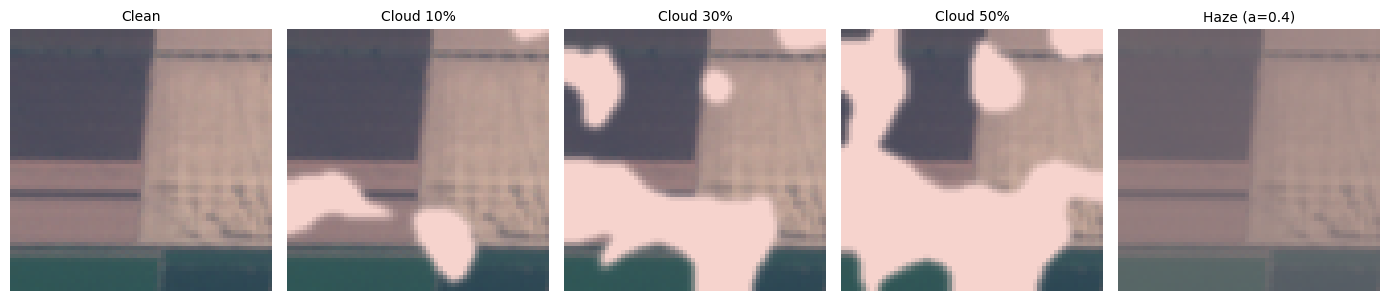

In [3]:
import scipy.ndimage as ndi
import matplotlib.pyplot as plt

# Data-driven signatures from TRAINING folds (fixes OOD blow-up in B9/B10 from hard-coded constants)
_rng = np.random.default_rng(0)
_sub = np.sort(_rng.choice(TRAIN_IDX, 800, replace=False))
_Xtr = np.array(X16_mmap[_sub, :13], dtype=np.float32)
CLOUD_SIG = np.array([np.percentile(_Xtr[:, b], 99.5) for b in range(13)], dtype=np.float32)[:, None, None]  # bright cloud
HAZE_SIG  = np.array([np.percentile(_Xtr[:, b], 90.0) for b in range(13)], dtype=np.float32)[:, None, None]  # milky veil
del _Xtr
print("CLOUD_SIG:", CLOUD_SIG.ravel().round(3))
print("HAZE_SIG :", HAZE_SIG.ravel().round(3))

def generate_perlin_cloud_masks(N, coverage=0.30, seed=42):
    rng = np.random.default_rng(seed)
    masks = np.zeros((N, 1, 64, 64), dtype=np.float32)
    for i in range(N):
        noise = rng.standard_normal((64, 64)).astype(np.float32)
        field = ndi.gaussian_filter(noise, sigma=8.0) + 0.5 * ndi.gaussian_filter(noise, sigma=4.0)
        thr = np.percentile(field, 100.0 * (1.0 - coverage))
        m = (field >= thr).astype(np.float32)
        # Soften cloud edges slightly
        m = np.clip(ndi.gaussian_filter(m, sigma=1.0) * 1.2, 0.0, 1.0)
        masks[i, 0] = m
    return masks

def apply_corruption_13ch(X13_clean, kind, param, seed=42):
    X = X13_clean.copy()
    N = len(X)
    rng = np.random.default_rng(seed)
    if kind == "clean":
        return X
    elif kind == "cloud":
        masks = generate_perlin_cloud_masks(N, coverage=float(param), seed=seed)
        X = X * (1.0 - masks) + CLOUD_SIG[None] * masks
        return np.clip(X, 0.0, 1.0)
    elif kind == "haze":
        alpha = float(param)
        X = (1.0 - alpha) * X + alpha * HAZE_SIG[None]
        return np.clip(X, 0.0, 1.0)
    elif kind == "band_drop":
        n_drop = int(param)
        for i in range(N):
            drop_b = rng.choice(13, size=n_drop, replace=False)
            X[i, drop_b] = 0.0
        return X
    elif kind == "group_drop":
        if param == "SWIR":
            X[:, [10, 11]] = 0.0       # B11, B12 (storage order: ...B9,B10,B11,B12,B8A)
        elif param == "RedEdge":
            X[:, [4, 5, 6, 12]] = 0.0  # B5, B6, B7, B8A (B8A is stored last)
        return X
    raise ValueError(f"Unknown corruption: {kind}")

# Visualize sample corruptions on one test patch
sample_idx = 10
demos = [
    ("Clean", apply_corruption_13ch(X13_test_clean[sample_idx:sample_idx+1], "clean", 0)[0]),
    ("Cloud 10%", apply_corruption_13ch(X13_test_clean[sample_idx:sample_idx+1], "cloud", 0.10)[0]),
    ("Cloud 30%", apply_corruption_13ch(X13_test_clean[sample_idx:sample_idx+1], "cloud", 0.30)[0]),
    ("Cloud 50%", apply_corruption_13ch(X13_test_clean[sample_idx:sample_idx+1], "cloud", 0.50)[0]),
    ("Haze (a=0.4)", apply_corruption_13ch(X13_test_clean[sample_idx:sample_idx+1], "haze", 0.40)[0]),
]
fig, axes = plt.subplots(1, len(demos), figsize=(14, 3))
for ax, (title, p13) in zip(axes, demos):
    rgb = np.clip(p13[[3, 2, 1]] / 0.3, 0, 1).transpose(1, 2, 0)
    ax.imshow(rgb); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/nb6_corruption_samples.png", dpi=140); plt.show()

## Cell 4 - Load Checkpoints (`B2`, `A3`, `A4`, `A5`) and Evaluation Helpers

In [5]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

IMG_MU = np.array(stats["phase1_train_folds_2_3_4"]["mean"], dtype=np.float32)
IMG_SD = np.array(stats["phase1_train_folds_2_3_4"]["std"], dtype=np.float32)

# Precompute TRAINING graph statistics from NB3 clean cache (never recomputed on test corruptions)
NSTAT_SPATIAL  = gm.graph_stats(G_clean, TRAIN_IDX, use_spectral=False)
NSTAT_SPECTRAL = gm.graph_stats(G_clean, TRAIN_IDX, use_spectral=True)

MODELS = {}
for code in ["A1", "A3", "A4", "A5"]:
    ckpt_p = find_one(f"best_{code}_K25m20.pt", required=False)
    if ckpt_p:
        spec = gm.EXPERIMENTS[code]
        mcfg = dict(spec, D=CFG.get("D", 128), heads=CFG.get("heads", 4), layers=CFG.get("layers", 2),
                    drop=CFG.get("drop_rate", 0.2), backbone=CFG.get("backbone", "tf_efficientnetv2_s.in21k_ft_in1k"),
                    img_size=CFG.get("img_size", 64))
        m = gm.GeoGraphNet(mcfg).to(DEVICE)
        m.load_state_dict(torch.load(ckpt_p, map_location=DEVICE))
        m.eval()
        MODELS[code] = m
        print(f"Loaded {code} from {ckpt_p}")

# Baselines from NB2 (same recipe, same normalisation). B1 = RGB CNN (channels B4,B3,B2 = idx 3,2,1), B2 = 16-ch CNN, B3 = Swin-Tiny 16-ch
BASELINES = {
    "B1": dict(ch=[3, 2, 1],        arch="cnn", ckpt="best_B1_rgb_cnn.pt"),
    "B2": dict(ch=list(range(16)),  arch="cnn", ckpt="best_B2_16ch_cnn.pt"),
    "B3": dict(ch=list(range(16)),  arch="vit", ckpt="best_B3_16ch_vit.pt"),
}
CNN_NAME = "tf_efficientnetv2_s.in21k_ft_in1k"; VIT_NAME = "swin_tiny_patch4_window7_224"
for code, spec in BASELINES.items():
    p = find_one(spec["ckpt"], required=False)
    if not p:
        print(f"WARNING: {spec['ckpt']} not found in Input -> {code} skipped (add the NB2 output dataset)")
        continue
    n_ch = len(spec["ch"])
    if spec["arch"] == "cnn":
        mb = timm.create_model(CNN_NAME, pretrained=False, in_chans=n_ch, num_classes=10, drop_rate=0.2)
    else:
        mb = timm.create_model(VIT_NAME, pretrained=False, in_chans=n_ch, num_classes=10, drop_rate=0.2, img_size=64, window_size=4)
    mb = mb.to(DEVICE); mb.load_state_dict(torch.load(p, map_location=DEVICE)); mb.eval()
    MODELS[code] = mb
    print(f"Loaded {code} ({n_ch} ch) from {p}")

def compute_ece(probs, labels, n_bins=15):
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    acc = (pred == labels).astype(np.float32); bins = np.linspace(0.0, 1.0, n_bins + 1); ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (conf > b0) & (conf <= b1)
        if m.any(): ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def eval_metrics(probs, labels):
    p = probs.argmax(axis=1)
    return dict(
        Acc=round(accuracy_score(labels, p) * 100, 3),
        Macro_F1=round(f1_score(labels, p, average="macro", zero_division=0) * 100, 3),
        Kappa=round(cohen_kappa_score(labels, p), 4),
        ECE=round(compute_ece(probs, labels), 4),
    )

@torch.no_grad()
def evaluate_all_models_on_corruption(X16_corr, G_corr):
    N = len(X16_corr)
    all_indices = np.arange(N)
    out_probs, out_gates = {}, {}

    for code, model in MODELS.items():
        if code in BASELINES:
            # Standard tensor evaluation for the NB2 baselines (channel subset + the same training-fold normalisation as NB2)
            ch = BASELINES[code]["ch"]
            X_norm = np.ascontiguousarray((X16_corr[:, ch] - IMG_MU[ch][None, :, None, None]) / (IMG_SD[ch][None, :, None, None] + 1e-6), dtype=np.float32)
            P = []
            for s in range(0, N, 256):
                xb = torch.from_numpy(X_norm[s:s+256]).to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type=="cuda")):
                    P.append(torch.softmax(model(xb).float(), dim=-1).cpu().numpy())
            out_probs[code] = np.concatenate(P, axis=0)
        else:
            use_spec = gm.EXPERIMENTS[code]["spectral"]
            nstat = NSTAT_SPECTRAL if use_spec else NSTAT_SPATIAL
            ds = gm.GraphDataset(all_indices, G_corr, X16_corr, y_test, IMG_MU, IMG_SD, nstat, use_spec, augment=False)
            dl = DataLoader(ds, batch_size=256, shuffle=False, num_workers=2, collate_fn=gm.collate)
            P, Gt = [], []
            for b in dl:
                b = {k: v.to(DEVICE, non_blocking=True) for k, v in b.items()}
                logits = model(b)
                P.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
                if getattr(model, "last_gate", None) is not None:
                    Gt.append(model.last_gate.cpu().numpy())
            out_probs[code] = np.concatenate(P, axis=0)
            if Gt:
                out_gates[code] = float(np.concatenate(Gt).mean())
    return out_probs, out_gates

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Loaded A1 from /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb4-v2-output/best_A1_K25m20.pt


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Loaded A3 from /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb4-v2-output/best_A3_K25m20.pt


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Loaded A4 from /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb4-v2-output/best_A4_K25m20.pt


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Loaded A5 from /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb4-v2-output/best_A5_K25m20.pt
Loaded B1 (3 ch) from /kaggle/input/datasets/sudeeptamandal/nb2-eurosat-output/best_B1_rgb_cnn.pt
Loaded B2 (16 ch) from /kaggle/input/datasets/sudeeptamandal/nb2-eurosat-output/best_B2_16ch_cnn.pt
Loaded B3 (16 ch) from /kaggle/input/datasets/sudeeptamandal/nb2-eurosat-output/best_B3_16ch_vit.pt


In [6]:
from sklearn.metrics import f1_score
z = np.load(find_one("nb2_probs.npz"))
for k in ["B1", "B2", "B3"]:
    print(k, "Macro-F1 from nb2_probs.npz: %.2f" % (f1_score(z["y_test"], z[f"test_{k}"].argmax(1), average="macro") * 100))

B1 Macro-F1 from nb2_probs.npz: 98.48
B2 Macro-F1 from nb2_probs.npz: 97.88
B3 Macro-F1 from nb2_probs.npz: 98.89


## Cell 4b - Clean reproducibility check (baselines on the stored NB1 tensor)

Evaluates B1/B2/B3 on the *stored* float16 X16 of the test fold (exactly what NB2 saw). Expected (NB2 fixed run): B1 about 98.48, B2 about 97.87, B3 about 98.89. A match means the inference path is correct; any difference in the Clean row of Cell 5 then comes from the recomputed indices / rebuilt graphs.


In [7]:
_all = dict(MODELS)
MODELS.clear(); MODELS.update({k: v for k, v in _all.items() if k in BASELINES})
X16_stored = np.array(X16_mmap[TEST_IDX], dtype=np.float32)
pm, _ = evaluate_all_models_on_corruption(X16_stored, None)
for k, p in pm.items():
    print(f"{k} on stored X16: Macro-F1 = {eval_metrics(p, y_test)['Macro_F1']:.2f}%")
MODELS.clear(); MODELS.update(_all)


B1 on stored X16: Macro-F1 = 98.48%
B2 on stored X16: Macro-F1 = 97.88%
B3 on stored X16: Macro-F1 = 98.89%


In [9]:
X16_re = make16_from_13(X13_test_clean)
_all = dict(MODELS); MODELS.clear(); MODELS.update({k: v for k, v in _all.items() if k in BASELINES})
def f1s(X):
    pm, _ = evaluate_all_models_on_corruption(X, None)
    return {k: round(eval_metrics(p, y_test)["Macro_F1"], 2) for k, p in pm.items()}
print("all recomputed      :", f1s(X16_re))
for name, c in [("only NDVI swapped", 13), ("only NDWI swapped", 14), ("only NDBI swapped", 15)]:
    X = X16_stored.copy(); X[:, c] = X16_re[:, c]
    print(f"{name:20s}:", f1s(X))
print("max abs diff per channel:", [round(float(np.abs(X16_re[:, c] - X16_stored[:, c]).max()), 5) for c in range(16)])
MODELS.clear(); MODELS.update(_all)

all recomputed      : {'B1': 98.48, 'B2': 97.88, 'B3': 98.89}
only NDVI swapped   : {'B1': 98.48, 'B2': 97.88, 'B3': 98.89}
only NDWI swapped   : {'B1': 98.48, 'B2': 97.88, 'B3': 98.89}
only NDBI swapped   : {'B1': 98.48, 'B2': 97.88, 'B3': 98.89}
max abs diff per channel: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.00054, 0.00054, 0.00054]


## Cell 5 - Run Full Robustness Suite (Recomputing Indices & Graphs per Corruption)

In [10]:
SCENARIOS = [
    ("Clean",      "clean",      0,         "0%"),
    ("Cloud_10",   "cloud",      0.10,      "10%"),
    ("Cloud_30",   "cloud",      0.30,      "30%"),
    ("Cloud_50",   "cloud",      0.50,      "50%"),
    ("Haze_0.2",   "haze",       0.20,      "0.2"),
    ("Haze_0.4",   "haze",       0.40,      "0.4"),
    ("Haze_0.6",   "haze",       0.60,      "0.6"),
    ("BandDrop_1", "band_drop",  1,         "1 band"),
    ("BandDrop_2", "band_drop",  2,         "2 bands"),
    ("BandDrop_4", "band_drop",  4,         "4 bands"),
    ("Drop_SWIR",  "group_drop", "SWIR",    "SWIR (B11, B12)"),
    ("Drop_RedEd", "group_drop", "RedEdge", "RedEdge (B5-7, B8A)"),
]

rows = []
saved_probs = {"y_test": y_test}

for sc_name, kind, param, level_str in SCENARIOS:
    t0 = time.time()
    # 1. Corrupt raw 13 bands
    X13_c = apply_corruption_13ch(X13_test_clean, kind, param, seed=42)
    # 2. Recompute 16 channels (13 bands + corrupted NDVI, NDWI, NDBI)
    X16_c = make16_from_13(X13_c)
    # 3. Rebuild SLIC + Dual-Topology graphs from corrupted image
    G_c = build_graph_dict_batch(X16_c, K=25, m=20)

    probs_map, gates_map = evaluate_all_models_on_corruption(X16_c, G_c)
    dt = time.time() - t0

    for code, pr in probs_map.items():
        m = eval_metrics(pr, y_test)
        m.update({
            "Scenario": sc_name,
            "Family": kind,
            "Level": level_str,
            "Model": code,
            "Gate_mean_CNN": round(gates_map.get(code, float("nan")), 4),
        })
        rows.append(m)
        saved_probs[f"{sc_name}_{code}"] = pr

    summary_str = " | ".join([f"{c}: F1={eval_metrics(p, y_test)['Macro_F1']:.2f}%" for c, p in probs_map.items()])
    print(f"[{sc_name:10s}] ({dt:4.1f}s) -> {summary_str}")
    if "A3" in probs_map:
        top = np.bincount(probs_map["A3"].argmax(1), minlength=10).max() / len(y_test)
        print(f"      A3 top-class share of predictions: {top:.2f}  (>0.5 => collapse / OOD corruption)")
    pd.DataFrame(rows).to_csv(f"{WORK}/nb6_robustness_metrics.csv", index=False)

np.savez_compressed(f"{WORK}/nb6_robustness_probs.npz", **saved_probs)
df_rob = pd.DataFrame(rows)
display(df_rob.pivot(index="Scenario", columns="Model", values=["Macro_F1", "ECE"]))

[Clean     ] (56.5s) -> A1: F1=98.81% | A3: F1=98.61% | A4: F1=98.79% | A5: F1=98.86% | B1: F1=98.48% | B2: F1=97.88% | B3: F1=98.89%
      A3 top-class share of predictions: 0.11  (>0.5 => collapse / OOD corruption)
[Cloud_10  ] (61.4s) -> A1: F1=95.56% | A3: F1=94.05% | A4: F1=94.24% | A5: F1=95.28% | B1: F1=82.36% | B2: F1=90.49% | B3: F1=92.02%
      A3 top-class share of predictions: 0.12  (>0.5 => collapse / OOD corruption)
[Cloud_30  ] (61.3s) -> A1: F1=80.43% | A3: F1=71.03% | A4: F1=70.70% | A5: F1=70.67% | B1: F1=52.63% | B2: F1=65.72% | B3: F1=67.21%
      A3 top-class share of predictions: 0.20  (>0.5 => collapse / OOD corruption)
[Cloud_50  ] (61.9s) -> A1: F1=42.20% | A3: F1=38.87% | A4: F1=34.75% | A5: F1=40.53% | B1: F1=27.80% | B2: F1=38.99% | B3: F1=40.01%
      A3 top-class share of predictions: 0.29  (>0.5 => collapse / OOD corruption)
[Haze_0.2  ] (56.9s) -> A1: F1=97.31% | A3: F1=96.30% | A4: F1=97.29% | A5: F1=97.38% | B1: F1=96.60% | B2: F1=96.59% | B3: F1=97.56

Macro_F1                                                     ECE  \
Model            A1      A3      A4      A5      B1      B2      B3      A1   
Scenario                                                                      
BandDrop_1   87.303  89.521  89.358  89.601  85.230  88.584  75.699  0.0610   
BandDrop_2   77.360  81.147  79.773  80.697  74.254  81.304  55.294  0.0582   
BandDrop_4   56.710  67.248  60.100  62.494  54.886  65.156  29.288  0.1553   
Clean        98.809  98.607  98.786  98.857  98.485  97.875  98.887  0.0764   
Cloud_10     95.558  94.049  94.239  95.280  82.364  90.493  92.022  0.0771   
Cloud_30     80.429  71.029  70.703  70.668  52.633  65.717  67.206  0.0973   
Cloud_50     42.197  38.871  34.751  40.527  27.802  38.995  40.007  0.0831   
Drop_RedEd   92.379  91.640  84.327  90.790  98.485  92.652  73.919  0.0596   
Drop_SWIR    76.883  87.167  79.847  77.558  98.485  80.633  45.930  0.0353   
Haze_0.2     97.310  96.300  97.288  97.384  96.601  96.591  97.556  0.0694   
Haze_0.4     82.457  81.028  78.987  81.752  81.612  85.707  81.586  0.0290   
Haze_0.6     45.208  57.601  36.093  51.163  51.422  47.619  41.445  0.2848   

                                                            
Model           A3      A4      A5      B1      B2      B3  
Scenario                                                    
BandDrop_1  0.0660  0.0660  0.0562  0.1054  0.0776  0.1090  
BandDrop_2  0.0588  0.0686  0.0582  0.1488  0.0642  0.2820  
BandDrop_4  0.0643  0.1215  0.1263  0.2189  0.0258  0.5088  
Clean       0.0791  0.0773  0.0743  0.0847  0.0829  0.0823  
Cloud_10    0.0830  0.0838  0.0870  0.0715  0.1202  0.0669  
Cloud_30    0.0541  0.0389  0.0361  0.0522  0.0616  0.1579  
Cloud_50    0.0503  0.0514  0.0830  0.1289  0.0601  0.3691  
Drop_RedEd  0.0628  0.0578  0.0401  0.0847  0.0904  0.0881  
Drop_SWIR   0.0475  0.0271  0.0281  0.0847  0.0487  0.3129  
Haze_0.2    0.0723  0.0704  0.0687  0.0841  0.0846  0.0753  
Haze_0.4    0.0353  0.0635  0.0378  0.0376  0.0619  0.0389  
Haze_0.6    0.2127  0.4018  0.2519  0.1924  0.1655  0.3463

In [13]:
print(df_rob[df_rob.Model == "A5"][["Scenario", "Gate_mean_CNN"]].to_string())

      Scenario  Gate_mean_CNN
3        Clean         0.5029
10    Cloud_10         0.5149
17    Cloud_30         0.5435
24    Cloud_50         0.5536
31    Haze_0.2         0.5038
38    Haze_0.4         0.5173
45    Haze_0.6         0.5314
52  BandDrop_1         0.5028
59  BandDrop_2         0.5024
66  BandDrop_4         0.4988
73   Drop_SWIR         0.4660
80  Drop_RedEd         0.4984


## Cell 6 - Degradation Curves & Reliability Diagrams (Calibration Audit)

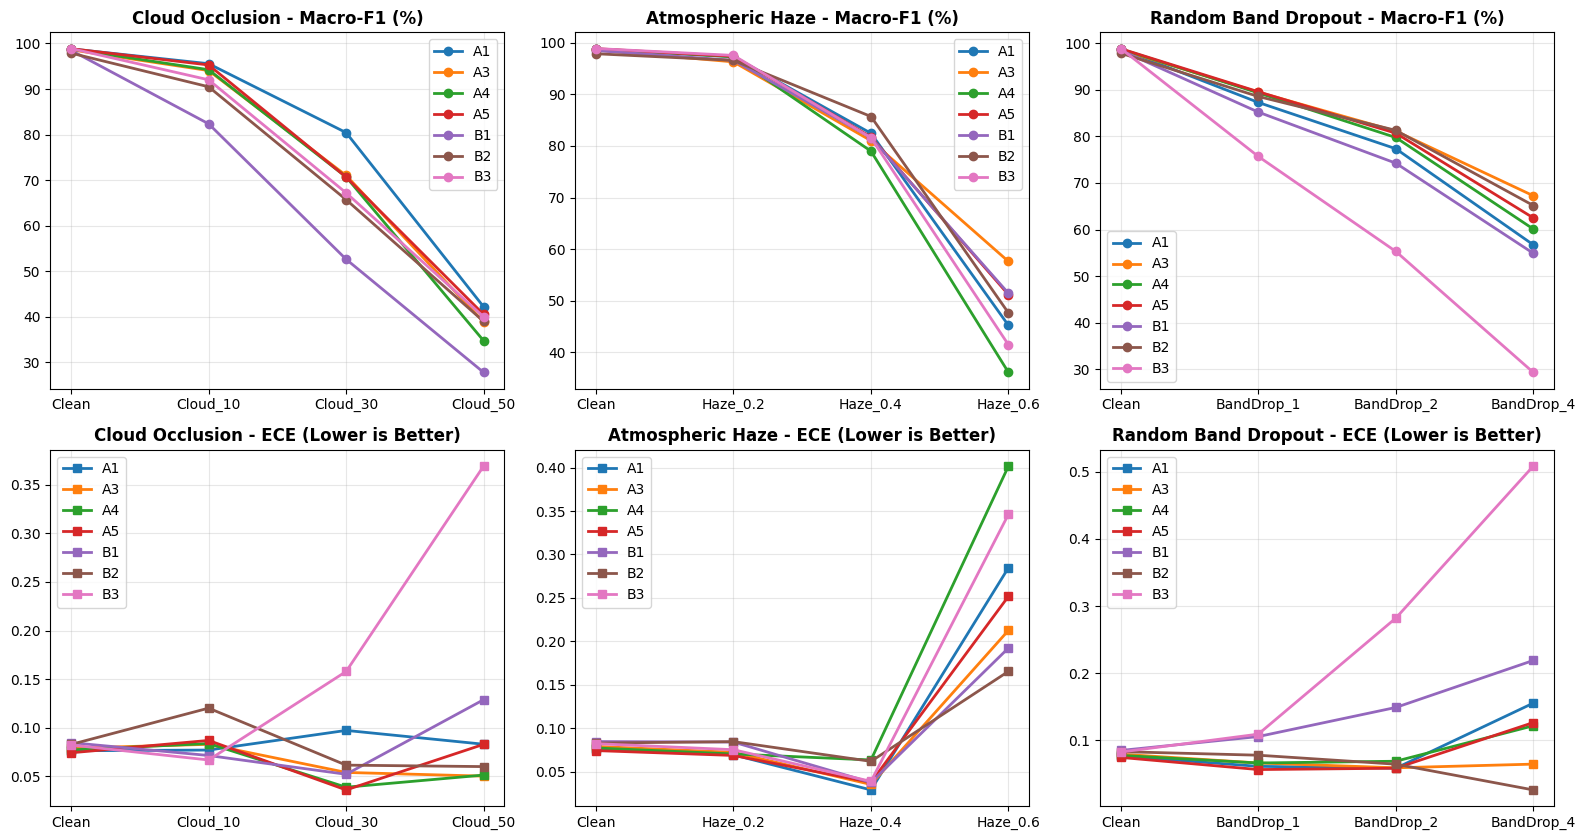

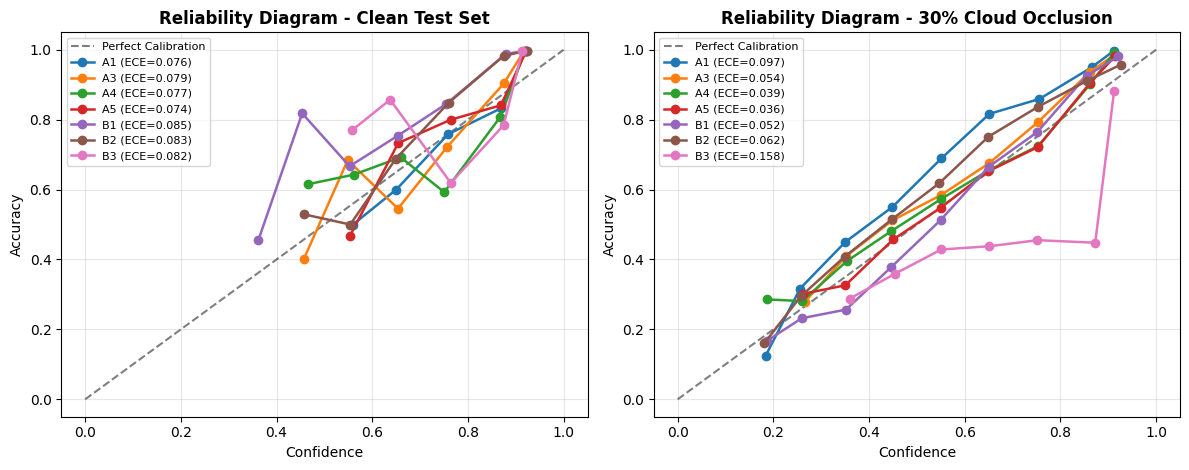

In [12]:
# 1. Plot Macro-F1 & ECE degradation curves across Cloud, Haze, and Band Dropout
families = [("cloud", "Cloud Occlusion", ["Clean", "Cloud_10", "Cloud_30", "Cloud_50"]),
            ("haze", "Atmospheric Haze", ["Clean", "Haze_0.2", "Haze_0.4", "Haze_0.6"]),
            ("band_drop", "Random Band Dropout", ["Clean", "BandDrop_1", "BandDrop_2", "BandDrop_4"])]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for col, (fam, title, order) in enumerate(families):
    sub = df_rob[df_rob["Scenario"].isin(order)].copy()
    sub["Scenario"] = pd.Categorical(sub["Scenario"], categories=order, ordered=True)
    sub = sub.sort_values("Scenario")
    for model_code, grp in sub.groupby("Model"):
        axes[0, col].plot(grp["Scenario"], grp["Macro_F1"], marker="o", lw=2, label=model_code)
        axes[1, col].plot(grp["Scenario"], grp["ECE"], marker="s", lw=2, label=model_code)
    axes[0, col].set_title(f"{title} - Macro-F1 (%)", fontweight="bold")
    axes[1, col].set_title(f"{title} - ECE (Lower is Better)", fontweight="bold")
    axes[0, col].grid(alpha=0.3); axes[1, col].grid(alpha=0.3)
    axes[0, col].legend(); axes[1, col].legend()

plt.tight_layout(); plt.savefig(f"{WORK}/nb6_degradation_curves.png", dpi=150); plt.show()

# 2. Reliability Diagrams on Clean vs 30% Cloud Occlusion
def plot_reliability(ax, probs, labels, title, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect Calibration")
    for code, pr in probs.items():
        conf, pred = pr.max(axis=1), pr.argmax(axis=1)
        acc = (pred == labels).astype(np.float32)
        xs, ys = [], []
        for b0, b1 in zip(bins[:-1], bins[1:]):
            m = (conf > b0) & (conf <= b1)
            if m.sum() > 10:
                xs.append(conf[m].mean()); ys.append(acc[m].mean())
        ax.plot(xs, ys, marker="o", lw=1.8, label=f"{code} (ECE={compute_ece(pr, labels):.3f})")
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
clean_p = {c: saved_probs[f"Clean_{c}"] for c in MODELS if f"Clean_{c}" in saved_probs}
cloud30_p = {c: saved_probs[f"Cloud_30_{c}"] for c in MODELS if f"Cloud_30_{c}" in saved_probs}
plot_reliability(ax[0], clean_p, y_test, "Reliability Diagram - Clean Test Set")
plot_reliability(ax[1], cloud30_p, y_test, "Reliability Diagram - 30% Cloud Occlusion")
plt.tight_layout(); plt.savefig(f"{WORK}/nb6_reliability_diagrams.png", dpi=150); plt.show()